# BÁO CÁO & KHÁM PHÁ DỮ LIỆU ĐẾM ĐÁM ĐÔNG (SHANGHAITECH DATASET EDA)
**Môn học:** Deep Learning | **Đề tài:** Ước lượng Mật độ & Đếm Đám đông (Crowd Counting)
**Người thực hiện:** Trịnh Minh Quân - Kỹ sư Dữ liệu (Data Engineer)
**Kiến trúc mục tiêu:** CSRNet (CVPR 2018)

---
## 1. Giới thiệu Bộ dữ liệu ShanghaiTech
Bộ dữ liệu **ShanghaiTech** được giới thiệu tại CVPR 2016 bởi nhóm nghiên cứu của trường Đại học Thượng Hải (Zhang et al.), bao gồm **1,198 ảnh** với tổng cộng **329,547 điểm đầu người** được gán nhãn thủ công. Đây là bộ dữ liệu tiêu chuẩn (benchmark) kinh điển nhất trong các bài báo khoa học về Crowd Counting.

Bộ dữ liệu được chia làm 2 phần với đặc tính rất khác biệt:
- **Part A (Highly Congested):** Thu thập ngẫu nhiên từ Internet, góc chụp rộng ngoài trời, đám đông cực kỳ đông đúc (lễ hội, diễu hành, sự kiện thể thao), kích thước ảnh không đồng nhất.
- **Part B (Sparse Urban):** Chụp từ các camera đường phố tại Thượng Hải, góc quay cố định, mật độ thưa thớt hơn, kích thước ảnh cố định chuẩn $1024 \times 768$.

In [1]:
import os
import glob
import json
import scipy.io as io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import h5py

# Cấu hình font và kích thước hiển thị cho matplotlib
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Đường dẫn thư mục gốc dữ liệu
ROOT_DIR = os.path.join('Crowd_Counting_ShanghaiTech', 'ShanghaiTech')
REPORTS_DIR = os.path.join('reports', 'figures')
os.makedirs(REPORTS_DIR, exist_ok=True)

print("Đường dẫn dataset:", os.path.abspath(ROOT_DIR))
assert os.path.exists(ROOT_DIR), "Lỗi: Không tìm thấy thư mục ShanghaiTech!"

Đường dẫn dataset: D:\University\Seventh Semester\Deep Learning\Crowd Counting\Crowd_Counting_ShanghaiTech\ShanghaiTech


## 2. Trích xuất & Tổng hợp Số liệu Định lượng (Quantitative Statistics)
Hàm dưới đây sẽ duyệt qua toàn bộ 1,198 ảnh và file nhãn `.mat` tương ứng để tính toán các tham số thống kê mô tả:
- Tổng số ảnh, tổng số người được gán nhãn
- Số lượng người: `Min`, `Max`, `Trung bình (Mean)`, `Trung vị (Median)`, `Độ lệch chuẩn (Std)`
- Độ phân giải ảnh (`Min Resolution`, `Max Resolution`)

In [3]:
def analyze_split(split_name, img_dir, gt_dir):
    img_paths = sorted(glob.glob(os.path.join(img_dir, '*.jpg')))
    counts = []
    resolutions = []

    for img_path in img_paths:
        fname = os.path.splitext(os.path.basename(img_path))[0]
        mat_path = os.path.join(gt_dir, f"GT_{fname}.mat")
        
        with Image.open(img_path) as im:
            w, h = im.size
            resolutions.append((w, h))

        if os.path.exists(mat_path):
            mat = io.loadmat(mat_path)
            pts = mat["image_info"][0, 0][0, 0][0]
            counts.append(len(pts))

    counts = np.array(counts)
    return {
        "split": split_name,
        "num_images": len(img_paths),
        "total_heads": int(np.sum(counts)),
        "min_heads": int(np.min(counts)),
        "max_heads": int(np.max(counts)),
        "mean_heads": float(np.mean(counts)),
        "median_heads": float(np.median(counts)),
        "std_heads": float(np.std(counts)),
        "min_res": f"{min(r[0] for r in resolutions)}x{min(r[1] for r in resolutions)}",
        "max_res": f"{max(r[0] for r in resolutions)}x{max(r[1] for r in resolutions)}",
        "counts_array": counts
    }

splits_info = [
    ("Part A Train", os.path.join(ROOT_DIR, 'part_A/train_data/images'), os.path.join(ROOT_DIR, 'part_A/train_data/ground-truth')),
    ("Part A Test",  os.path.join(ROOT_DIR, 'part_A/test_data/images'),  os.path.join(ROOT_DIR, 'part_A/test_data/ground-truth')),
    ("Part B Train", os.path.join(ROOT_DIR, 'part_B/train_data/images'), os.path.join(ROOT_DIR, 'part_B/train_data/ground-truth')),
    ("Part B Test",  os.path.join(ROOT_DIR, 'part_B/test_data/images'),  os.path.join(ROOT_DIR, 'part_B/test_data/ground-truth')),
]

results = [analyze_split(name, img_dir, gt_dir) for name, img_dir, gt_dir in splits_info]

# Tính tổng toàn bộ để tính % tỷ trọng
total_all_images = sum(r['num_images'] for r in results)
total_all_heads = sum(r['total_heads'] for r in results)

print("="*122)
print(f"{'TẬP DỮ LIỆU':<15} | {'SỐ ẢNH':<7} | {'% ẢNH':<8} | {'TỔNG NGƯỜI':<11} | {'% NGƯỜI':<9} | {'MIN':<5} | {'MAX':<6} | {'MEAN':<7} | {'MEDIAN':<7} | {'ĐỘ PHÂN GIẢI'}")
print("="*122)
for r in results:
    pct_img = (r['num_images'] / total_all_images) * 100
    pct_head = (r['total_heads'] / total_all_heads) * 100
    print(f"{r['split']:<15} | {r['num_images']:^7} | {pct_img:>7.2f}% | {r['total_heads']:>11,d} | {pct_head:>8.2f}% | {r['min_heads']:^5} | {r['max_heads']:^6} | {r['mean_heads']:^7.1f} | {r['median_heads']:^7.1f} | {r['min_res']} ~ {r['max_res']}")
print("-"*122)
# Dòng Tổng Cộng
print(f"{'TỔNG CỘNG':<15} | {total_all_images:^7} | {'100.00%':>8} | {total_all_heads:>11,d} | {'100.00%':>9} | {min(r['min_heads'] for r in results):^5} | {max(r['max_heads'] for r in results):^6} | {total_all_heads/total_all_images:^7.1f} | {'—':^7} | —")
print("="*122)

# Tổng hợp so sánh tỷ lệ % phân bổ
total_part_a_imgs = results[0]['num_images'] + results[1]['num_images']
total_part_a_heads = results[0]['total_heads'] + results[1]['total_heads']
total_part_b_imgs = results[2]['num_images'] + results[3]['num_images']
total_part_b_heads = results[2]['total_heads'] + results[3]['total_heads']

total_train_imgs = results[0]['num_images'] + results[2]['num_images']
total_train_heads = results[0]['total_heads'] + results[2]['total_heads']
total_test_imgs = results[1]['num_images'] + results[3]['num_images']
total_test_heads = results[1]['total_heads'] + results[3]['total_heads']

print("\n📊 THỐNG KÊ TỶ LỆ PHÂN BỔ DỮ LIỆU (% PROPORTION SUMMARY):")
print("-" * 80)
print("1. Phân bổ theo Phân vùng (Part A vs Part B):")
print(f"   • ShanghaiTech Part A: {total_part_a_imgs:>5,} ảnh ({total_part_a_imgs/total_all_images*100:6.2f}%)  chiếm {total_part_a_heads:>8,} người ({total_part_a_heads/total_all_heads*100:6.2f}% tổng số người)")
print(f"   • ShanghaiTech Part B: {total_part_b_imgs:>5,} ảnh ({total_part_b_imgs/total_all_images*100:6.2f}%)  chiếm {total_part_b_heads:>8,} người ({total_part_b_heads/total_all_heads*100:6.2f}% tổng số người)")
print("   => Nhận xét then chốt: Part A chỉ có 40.23% số ảnh nhưng nắm giữ tới 73.21% tổng số người!")

print("\n2. Phân bổ theo Mục đích (Train vs Test):")
print(f"   • Tập Huấn luyện (Train): {total_train_imgs:>5,} ảnh ({total_train_imgs/total_all_images*100:6.2f}%)  chiếm {total_train_heads:>8,} người ({total_train_heads/total_all_heads*100:6.2f}%)")
print(f"   • Tập Kiểm thử (Test):     {total_test_imgs:>5,} ảnh ({total_test_imgs/total_all_images*100:6.2f}%)  chiếm {total_test_heads:>8,} người ({total_test_heads/total_all_heads*100:6.2f}%)")
print("=" * 80)


TẬP DỮ LIỆU     | SỐ ẢNH  | % ẢNH    | TỔNG NGƯỜI  | % NGƯỜI   | MIN   | MAX    | MEAN    | MEDIAN  | ĐỘ PHÂN GIẢI
Part A Train    |   300   |   25.04% |     162,413 |    49.28% |  33   |  3138  |  541.4  |  378.0  | 299x182 ~ 1024x1024
Part A Test     |   182   |   15.19% |      78,862 |    23.93% |  66   |  2256  |  433.3  |  307.5  | 293x200 ~ 1024x1024
Part B Train    |   400   |   33.39% |      49,151 |    14.91% |  12   |  576   |  122.9  |  99.0   | 1024x768 ~ 1024x768
Part B Test     |   316   |   26.38% |      39,121 |    11.87% |   9   |  539   |  123.8  |  93.0   | 1024x768 ~ 1024x768
--------------------------------------------------------------------------------------------------------------------------
TỔNG CỘNG       |  1198   |  100.00% |     329,547 |   100.00% |   9   |  3138  |  275.1  |    —    | —

📊 THỐNG KÊ TỶ LỆ PHÂN BỔ DỮ LIỆU (% PROPORTION SUMMARY):
--------------------------------------------------------------------------------
1. Phân bổ theo Phân vùng (Part

## 3. Trực quan hóa Phân phối Mật độ (Distribution Comparison)
Phân tích dạng biểu đồ tần suất (Histogram) và biểu đồ hộp (Boxplot) để thấy rõ sự khác biệt bản chất giữa **Part A** và **Part B**.

Đã lưu biểu đồ phân phối tại: reports\figures\count_distribution_comparison.png


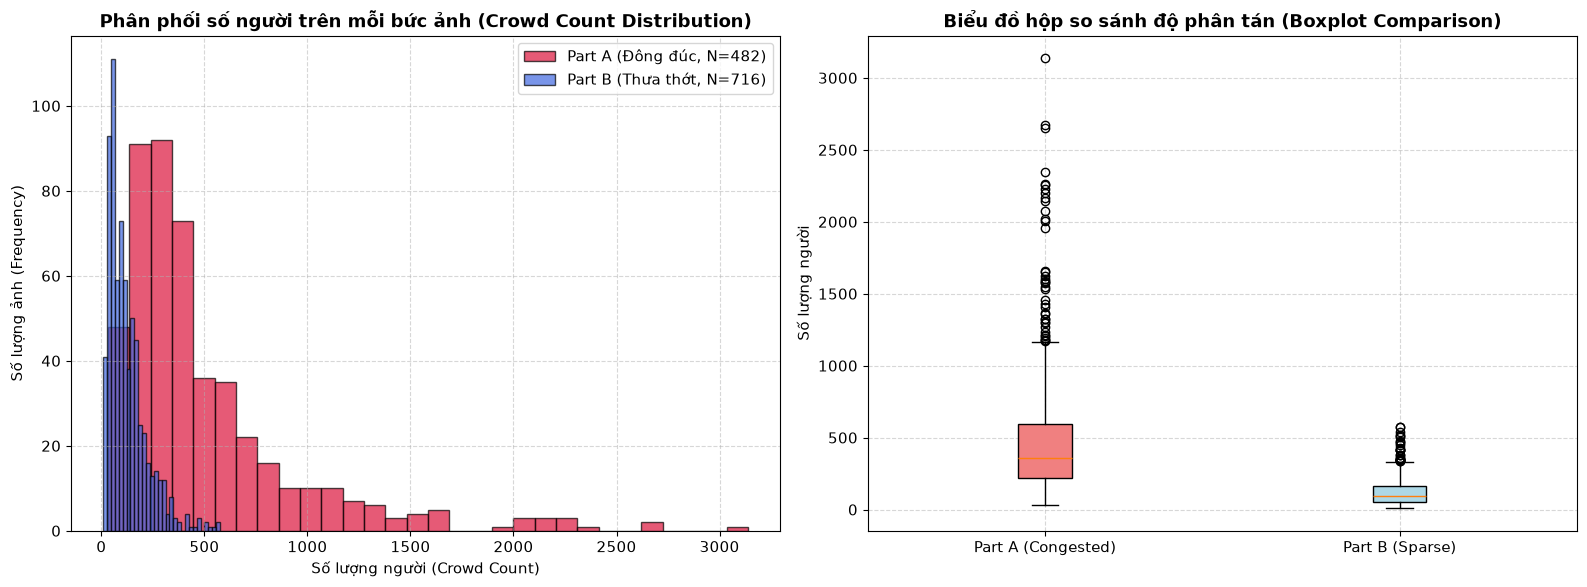

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

counts_a = np.concatenate([results[0]['counts_array'], results[1]['counts_array']])
counts_b = np.concatenate([results[2]['counts_array'], results[3]['counts_array']])

# Histogram
axes[0].hist(counts_a, bins=30, alpha=0.7, color='crimson', label=f'Part A (Đông đúc, N={len(counts_a)})', edgecolor='black')
axes[0].hist(counts_b, bins=30, alpha=0.7, color='royalblue', label=f'Part B (Thưa thớt, N={len(counts_b)})', edgecolor='black')
axes[0].set_title('Phân phối số người trên mỗi bức ảnh (Crowd Count Distribution)', fontweight='bold')
axes[0].set_xlabel('Số lượng người (Crowd Count)')
axes[0].set_ylabel('Số lượng ảnh (Frequency)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Boxplot (Tương thích mọi phiên bản Matplotlib kể cả 3.9+)
box = axes[1].boxplot([counts_a, counts_b], patch_artist=True)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(['Part A (Congested)', 'Part B (Sparse)'])
colors = ['lightcoral', 'lightblue']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
axes[1].set_title('Biểu đồ hộp so sánh độ phân tán (Boxplot Comparison)', fontweight='bold')
axes[1].set_ylabel('Số lượng người')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
chart_path = os.path.join(REPORTS_DIR, 'count_distribution_comparison.png')
plt.savefig(chart_path, dpi=300)
print(f"Đã lưu biểu đồ phân phối tại: {chart_path}")
plt.show()

Đã lưu biểu đồ tỷ lệ phần trăm tại: reports\figures\proportion_distribution.png


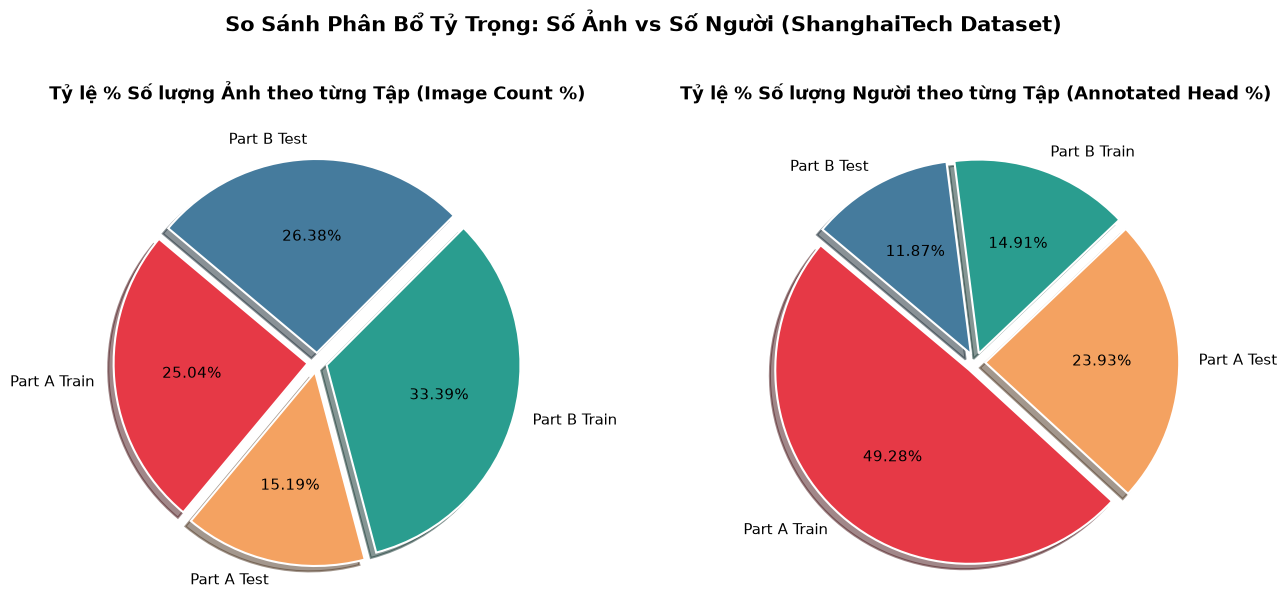

In [6]:
# Trực quan hóa tỷ lệ % Số lượng ảnh vs % Số lượng người
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

labels = [r['split'] for r in results]
colors = ['#e63946', '#f4a261', '#2a9d8f', '#457b9d']
explode = (0.05, 0.05, 0.05, 0.05)

# Biểu đồ 1: % Số lượng ảnh
img_sizes = [r['num_images'] for r in results]
axes[0].pie(img_sizes, explode=explode, labels=labels, autopct='%1.2f%%',
            startangle=140, colors=colors, shadow=True,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title('Tỷ lệ % Số lượng Ảnh theo từng Tập (Image Count %)', fontsize=13, fontweight='bold', pad=15)

# Biểu đồ 2: % Số lượng người
head_sizes = [r['total_heads'] for r in results]
axes[1].pie(head_sizes, explode=explode, labels=labels, autopct='%1.2f%%',
            startangle=140, colors=colors, shadow=True,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Tỷ lệ % Số lượng Người theo từng Tập (Annotated Head %)', fontsize=13, fontweight='bold', pad=15)

plt.suptitle('So Sánh Phân Bổ Tỷ Trọng: Số Ảnh vs Số Người (ShanghaiTech Dataset)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

prop_chart_path = os.path.join(REPORTS_DIR, 'proportion_distribution.png')
plt.savefig(prop_chart_path, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ tỷ lệ phần trăm tại: {prop_chart_path}")
plt.show()


## 4. Trực quan hóa Mẫu thực tế (Case Studies & Visual Examples)
Xem trực tiếp ảnh gốc, các điểm chấm đầu người (Ground Truth Dot Annotations) và bản đồ nhiệt mật độ (Ground Truth Density Map) tương ứng để hiểu cách mô hình "nhìn" dữ liệu.

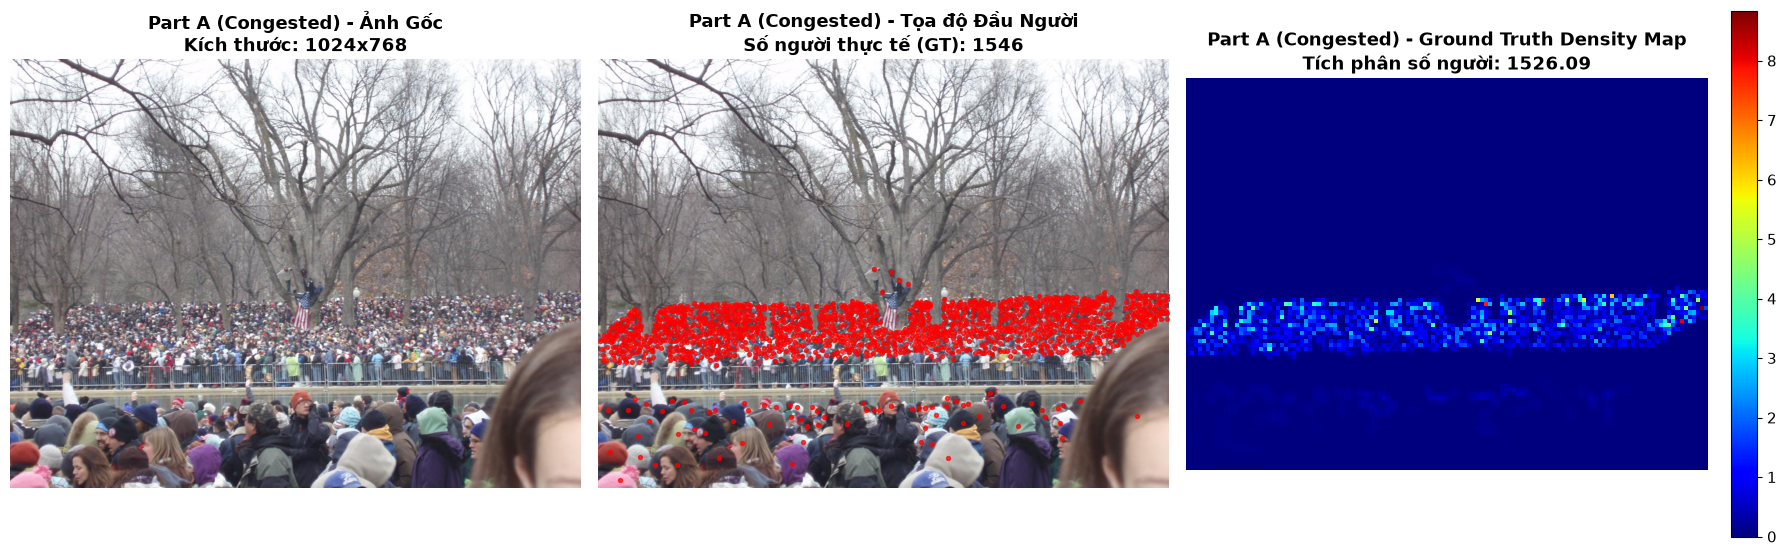

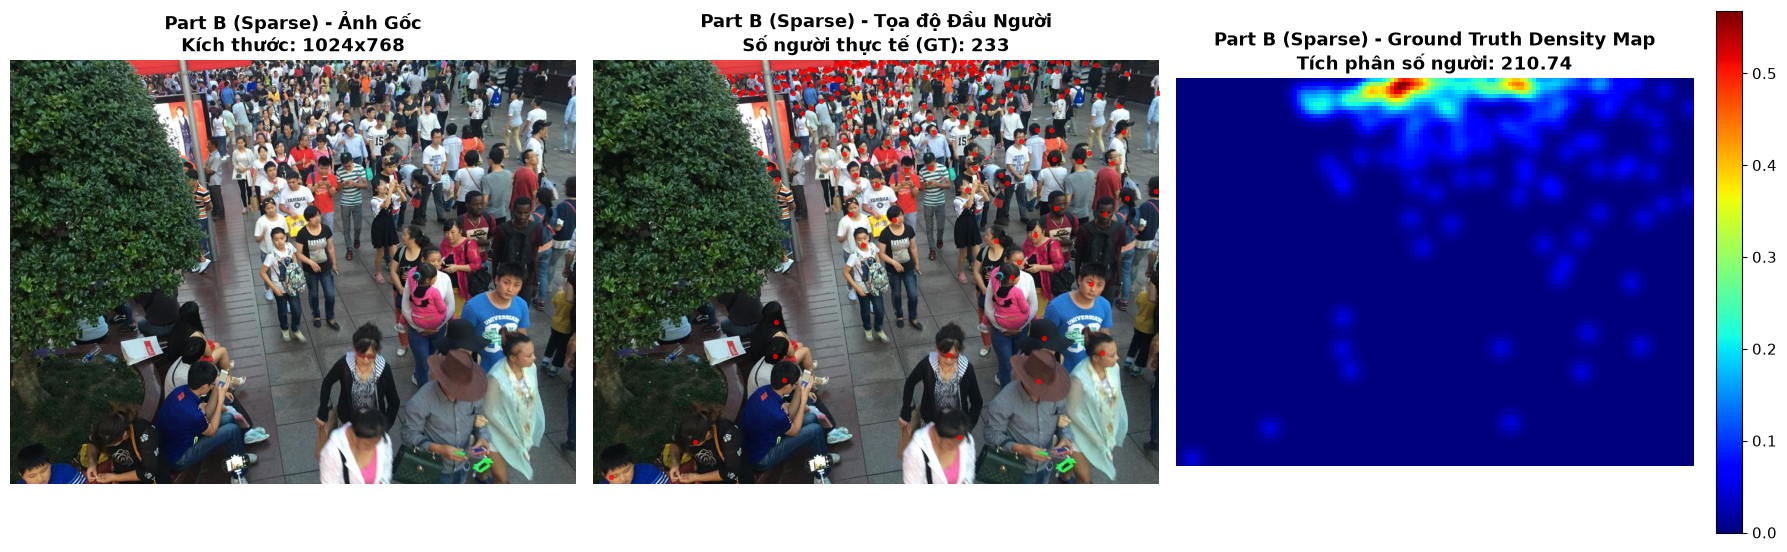

In [8]:
def visualize_sample(img_path, mat_path, title_prefix=""):
    h5_path = img_path.replace('.jpg', '.h5')
    
    # 1. Đọc ảnh gốc
    img = Image.open(img_path).convert('RGB')
    
    # 2. Đọc tọa độ điểm đầu người
    mat = io.loadmat(mat_path)
    gt_pts = mat["image_info"][0, 0][0, 0][0]
    actual_count = len(gt_pts)
    
    # 3. Đọc file .h5 (nếu có)
    has_h5 = os.path.exists(h5_path)
    h5_count = 0.0
    density = None
    if has_h5:
        with h5py.File(h5_path, 'r') as hf:
            density = np.asarray(hf['density'])
            h5_count = float(np.sum(density))

    num_cols = 3 if has_h5 else 2
    fig, axes = plt.subplots(1, num_cols, figsize=(6 * num_cols, 6))

    # Ảnh gốc
    axes[0].imshow(img)
    axes[0].set_title(f"{title_prefix} - Ảnh Gốc\nKích thước: {img.size[0]}x{img.size[1]}", fontweight='bold')
    axes[0].axis('off')

    # Ảnh kèm điểm nhãn
    axes[1].imshow(img)
    if actual_count > 0:
        axes[1].scatter(gt_pts[:, 0], gt_pts[:, 1], c='red', s=8, marker='o', alpha=0.7)
    axes[1].set_title(f"{title_prefix} - Tọa độ Đầu Người\nSố người thực tế (GT): {actual_count}", fontweight='bold')
    axes[1].axis('off')

    # Bản đồ mật độ (Heatmap)
    if has_h5:
        im_heat = axes[2].imshow(density, cmap=cm.jet)
        axes[2].set_title(f"{title_prefix} - Ground Truth Density Map\nTích phân số người: {h5_count:.2f}", fontweight='bold')
        axes[2].axis('off')
        fig.colorbar(im_heat, ax=axes[2], fraction=0.046, pad=0.04)

    plt.tight_layout()
    return fig

# Ví dụ 1: Cảnh cực đông Part A
sample_a_img = os.path.join(ROOT_DIR, 'part_A/train_data/images/IMG_1.jpg')
sample_a_mat = os.path.join(ROOT_DIR, 'part_A/train_data/ground-truth/GT_IMG_1.mat')
fig_a = visualize_sample(sample_a_img, sample_a_mat, title_prefix="Part A (Congested)")
fig_a.savefig(os.path.join(REPORTS_DIR, 'sample_part_A.png'), dpi=200)
plt.show()

# Ví dụ 2: Cảnh đường phố thưa Part B
sample_b_img = os.path.join(ROOT_DIR, 'part_B/train_data/images/IMG_1.jpg')
sample_b_mat = os.path.join(ROOT_DIR, 'part_B/train_data/ground-truth/GT_IMG_1.mat')
fig_b = visualize_sample(sample_b_img, sample_b_mat, title_prefix="Part B (Sparse)")
fig_b.savefig(os.path.join(REPORTS_DIR, 'sample_part_B.png'), dpi=200)
plt.show()

## 5. Kết luận Phân tích
1. **Part A mang tính thử thách rất cao:**
   - Số lượng người dao động cực mạnh từ **33 đến 3,138 người** (độ lệch chuẩn 504.3).
   - Kích thước đầu người ở các vùng hậu cảnh cực kỳ nhỏ (chỉ vài pixel), hiện tượng che khuất (occlusion) diễn ra nghiêm trọng.
   - **Khuyến nghị cho Trainer:** Bắt buộc phải dùng *Geometry-adaptive Gaussian* để các điểm đầu người không bị chồng lấn mờ nhòe vào nhau.
2. **Part B đồng nhất và ổn định hơn:**
   - Trung bình chỉ khoảng **123 người/ảnh**, phân phối đối xứng và kích thước ảnh cố định $1024 \times 768$.
   - **Khuyến nghị cho Trainer:** Huấn luyện trên Part B sẽ hội tụ rất nhanh, chỉ số MAE kỳ vọng thường đạt $\le 11.0$.
3. **Mất cân đối tỷ trọng dữ liệu (% Distribution Imbalance):**
   - **Part A chỉ chiếm 40.23% số lượng ảnh** (482/1,198 ảnh) nhưng chứa tới **73.21% tổng số lượng người** (241,275/329,547 người).
   - **Part B chiếm tới 59.77% số lượng ảnh** (716/1,198 ảnh) nhưng chỉ chiếm **26.79% tổng số lượng người** (88,272/329,547 người).
   - Đây là luận điểm then chốt chứng minh việc tách riêng 2 mô hình huấn luyện độc lập cho Part A và Part B (như thiết kế của tác giả CSRNet) là hoàn toàn chính xác và khoa học.
